In [1]:
library(tidyverse)
library(bigrquery)

# This query represents dataset "diabetes" for domain "fitbit_activity" and was generated for All of Us Controlled Tier Dataset v8
dataset_57359454_fitbit_activity_sql <- paste("
    SELECT
        activity_summary.person_id,
        activity_summary.date,
        activity_summary.activity_calories,
        activity_summary.calories_bmr,
        activity_summary.calories_out,
        activity_summary.elevation,
        activity_summary.fairly_active_minutes,
        activity_summary.floors,
        activity_summary.lightly_active_minutes,
        activity_summary.marginal_calories,
        activity_summary.sedentary_minutes,
        activity_summary.steps,
        activity_summary.very_active_minutes 
    FROM
        `activity_summary` activity_summary   
    WHERE
        activity_summary.PERSON_ID IN (SELECT
            distinct person_id  
        FROM
            `cb_search_person` cb_search_person  
        WHERE
            cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_activity_summary = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_plus_device_information = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_heart_rate_summary = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_heart_rate_level = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_steps_intraday = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_sleep_daily_summary = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_sleep_level = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                criteria.person_id 
            FROM
                (SELECT
                    DISTINCT person_id, entry_date, concept_id 
                FROM
                    `cb_search_all_events` 
                WHERE
                    (concept_id IN(SELECT
                        DISTINCT c.concept_id 
                    FROM
                        `cb_criteria` c 
                    JOIN
                        (SELECT
                            CAST(cr.id as string) AS id       
                        FROM
                            `cb_criteria` cr       
                        WHERE
                            concept_id IN (201820)       
                            AND full_text LIKE '%_rank1]%'      ) a 
                            ON (c.path LIKE CONCAT('%.', a.id, '.%') 
                            OR c.path LIKE CONCAT('%.', a.id) 
                            OR c.path LIKE CONCAT(a.id, '.%') 
                            OR c.path = a.id) 
                    WHERE
                        is_standard = 1 
                        AND is_selectable = 1) 
                    AND is_standard = 1 )) criteria ) )", sep="")

# Formulate a Cloud Storage destination path for the data exported from BigQuery.
# NOTE: By default data exported multiple times on the same day will overwrite older copies.
#       But data exported on a different days will write to a new location so that historical
#       copies can be kept as the dataset definition is changed.
fitbit_activity_57359454_path <- file.path(
  Sys.getenv("WORKSPACE_BUCKET"),
  "bq_exports",
  Sys.getenv("OWNER_EMAIL"),
  strftime(lubridate::now(), "%Y%m%d"),  # Comment out this line if you want the export to always overwrite.
  "fitbit_activity_57359454",
  "fitbit_activity_57359454_*.csv")
message(str_glue('The data will be written to {fitbit_activity_57359454_path}. Use this path when reading ',
                 'the data into your notebooks in the future.'))

# Perform the query and export the dataset to Cloud Storage as CSV files.
# NOTE: You only need to run `bq_table_save` once. After that, you can
#       just read data from the CSVs in Cloud Storage.
bq_table_save(
  bq_dataset_query(Sys.getenv("WORKSPACE_CDR"), dataset_57359454_fitbit_activity_sql, billing = Sys.getenv("GOOGLE_PROJECT")),
  fitbit_activity_57359454_path,
  destination_format = "CSV")



── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
The data will be written to gs://fc-secure-1d0240db-6bfa-4a11-a526-48cfbb0d664a/bq_exports/zqiu@researchallofus.org/20260427/fitbit_activity_57359454/fitbit_activity_57359454_*.csv. Use this path when reading the data into your notebooks in the future.



In [2]:
# Read the data directly from Cloud Storage into memory.
# NOTE: Alternatively you can `gsutil -m cp {fitbit_activity_57359454_path}` to copy these files
#       to the Jupyter disk.
read_bq_export_from_workspace_bucket <- function(export_path) {
  col_types <- NULL
  bind_rows(
    map(system2('gsutil', args = c('ls', export_path), stdout = TRUE, stderr = TRUE),
        function(csv) {
          message(str_glue('Loading {csv}.'))
          chunk <- read_csv(pipe(str_glue('gsutil cat {csv}')), col_types = col_types, show_col_types = FALSE)
          if (is.null(col_types)) {
            col_types <- spec(chunk)
          }
          chunk
        }))
}
diabetes_activity <- read_bq_export_from_workspace_bucket(fitbit_activity_57359454_path)

dim(diabetes_activity)

head(diabetes_activity, 5)

Loading gs://fc-secure-1d0240db-6bfa-4a11-a526-48cfbb0d664a/bq_exports/zqiu@researchallofus.org/20260427/fitbit_activity_57359454/fitbit_activity_57359454_000000000000.csv.



[1] 3159193      13

person_id,date,activity_calories,calories_bmr,calories_out,elevation,fairly_active_minutes,floors,lightly_active_minutes,marginal_calories,sedentary_minutes,steps,very_active_minutes
<dbl>,<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
9337412,2022-07-05,648,NA,2778,NA,0,NA,176,NA,808,591,0
9337412,2022-06-27,0,NA,2402,NA,0,NA,0,NA,1440,0,0
9337412,2022-06-28,0,NA,2402,NA,0,NA,0,NA,1440,0,0
9337412,2022-06-26,0,NA,2402,NA,0,NA,0,NA,1440,0,0
9337412,2022-07-02,0,NA,2402,NA,0,NA,0,NA,1440,0,0


In [6]:
# This query represents dataset "diabetes" for domain "person" and was generated for All of Us Controlled Tier Dataset v8
dataset_57359454_person_sql <- paste("
    SELECT
        person.person_id,
        person.birth_datetime as date_of_birth,
        person.race_concept_id,
        p_race_concept.concept_name as race,
        person.ethnicity_concept_id,
        p_ethnicity_concept.concept_name as ethnicity,
        person.sex_at_birth_concept_id,
        p_sex_at_birth_concept.concept_name as sex_at_birth,
        person.self_reported_category_concept_id,
        p_self_reported_category_concept.concept_name as self_reported_category 
    FROM
        `person` person 
    LEFT JOIN
        `concept` p_race_concept 
            ON person.race_concept_id = p_race_concept.concept_id 
    LEFT JOIN
        `concept` p_ethnicity_concept 
            ON person.ethnicity_concept_id = p_ethnicity_concept.concept_id 
    LEFT JOIN
        `concept` p_sex_at_birth_concept 
            ON person.sex_at_birth_concept_id = p_sex_at_birth_concept.concept_id 
    LEFT JOIN
        `concept` p_self_reported_category_concept 
            ON person.self_reported_category_concept_id = p_self_reported_category_concept.concept_id  
    WHERE
        person.PERSON_ID IN (SELECT
            distinct person_id  
        FROM
            `cb_search_person` cb_search_person  
        WHERE
            cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_activity_summary = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_plus_device_information = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_heart_rate_summary = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_heart_rate_level = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_steps_intraday = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_sleep_daily_summary = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_sleep_level = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                criteria.person_id 
            FROM
                (SELECT
                    DISTINCT person_id, entry_date, concept_id 
                FROM
                    `cb_search_all_events` 
                WHERE
                    (concept_id IN(SELECT
                        DISTINCT c.concept_id 
                    FROM
                        `cb_criteria` c 
                    JOIN
                        (SELECT
                            CAST(cr.id as string) AS id       
                        FROM
                            `cb_criteria` cr       
                        WHERE
                            concept_id IN (201820)       
                            AND full_text LIKE '%_rank1]%'      ) a 
                            ON (c.path LIKE CONCAT('%.', a.id, '.%') 
                            OR c.path LIKE CONCAT('%.', a.id) 
                            OR c.path LIKE CONCAT(a.id, '.%') 
                            OR c.path = a.id) 
                    WHERE
                        is_standard = 1 
                        AND is_selectable = 1) 
                    AND is_standard = 1 )) criteria ) )", sep="")

# Formulate a Cloud Storage destination path for the data exported from BigQuery.
# NOTE: By default data exported multiple times on the same day will overwrite older copies.
#       But data exported on a different days will write to a new location so that historical
#       copies can be kept as the dataset definition is changed.
person_57359454_path <- file.path(
  Sys.getenv("WORKSPACE_BUCKET"),
  "bq_exports",
  Sys.getenv("OWNER_EMAIL"),
  strftime(lubridate::now(), "%Y%m%d"),  # Comment out this line if you want the export to always overwrite.
  "person_57359454",
  "person_57359454_*.csv")
message(str_glue('The data will be written to {person_57359454_path}. Use this path when reading ',
                 'the data into your notebooks in the future.'))

# Perform the query and export the dataset to Cloud Storage as CSV files.
# NOTE: You only need to run `bq_table_save` once. After that, you can
#       just read data from the CSVs in Cloud Storage.
bq_table_save(
  bq_dataset_query(Sys.getenv("WORKSPACE_CDR"), dataset_57359454_person_sql, billing = Sys.getenv("GOOGLE_PROJECT")),
  person_57359454_path,
  destination_format = "CSV")

The data will be written to gs://fc-secure-1d0240db-6bfa-4a11-a526-48cfbb0d664a/bq_exports/zqiu@researchallofus.org/20260427/person_57359454/person_57359454_*.csv. Use this path when reading the data into your notebooks in the future.



In [10]:
# Read the data directly from Cloud Storage into memory.
# NOTE: Alternatively you can `gsutil -m cp {person_57359454_path}` to copy these files
#       to the Jupyter disk.
read_bq_export_from_workspace_bucket <- function(export_path) {
  col_types <- cols(race = col_character(), ethnicity = col_character(), sex_at_birth = col_character(), self_reported_category = col_character())
  bind_rows(
    map(system2('gsutil', args = c('ls', export_path), stdout = TRUE, stderr = TRUE),
        function(csv) {
          message(str_glue('Loading {csv}.'))
          chunk <- read_csv(pipe(str_glue('gsutil cat {csv}')), col_types = col_types, show_col_types = FALSE)
          if (is.null(col_types)) {
            col_types <- spec(chunk)
          }
          chunk
        }))
}
diabetes_meta <- read_bq_export_from_workspace_bucket(person_57359454_path)

dim(diabetes_meta)

head(diabetes_meta, 5)

Loading gs://fc-secure-1d0240db-6bfa-4a11-a526-48cfbb0d664a/bq_exports/zqiu@researchallofus.org/20260427/person_57359454/person_57359454_000000000000.csv.



[1] 4783   10

person_id,date_of_birth,race_concept_id,race,ethnicity_concept_id,ethnicity,sex_at_birth_concept_id,sex_at_birth,self_reported_category_concept_id,self_reported_category
<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>
5518863,1947-06-15 00:00:00 UTC,8527,White,38003563,Hispanic or Latino,903096,PMI: Skip,2e+09,More than one population
1675767,1984-06-15 00:00:00 UTC,2000000008,More than one population,38003564,Not Hispanic or Latino,903096,PMI: Skip,2e+09,More than one population
7489870,1983-06-15 00:00:00 UTC,2000000008,More than one population,38003564,Not Hispanic or Latino,46273637,Intersex,2e+09,More than one population
2659184,1949-06-15 00:00:00 UTC,38003615,Middle Eastern or North African,38003563,Hispanic or Latino,45880669,Male,2e+09,More than one population
4874844,1955-06-15 00:00:00 UTC,8657,American Indian or Alaska Native,38003563,Hispanic or Latino,45880669,Male,2e+09,More than one population


In [20]:
source('/home/jupyter/workspaces/temporaldigitalhealthphenotyping/ind_descriptive_func.R')

In [23]:
wear_compliance_func(path.out = '/home/jupyter/workspaces/result/Diabetes/', df = diabetes_activity)

── Wear compliance ──
     n_days       followup_days   
 Min.   :   1.0   Min.   :   1.0  
 1st Qu.:  96.0   1st Qu.: 104.0  
 Median : 247.0   Median : 420.0  
 Mean   : 660.5   Mean   : 933.8  
 3rd Qu.: 990.0   3rd Qu.:1521.5  
 Max.   :5386.0   Max.   :5386.0  


`geom_smooth()` using formula = 'y ~ x'


   person_id           n_days         first_date           last_date         
 Min.   :1000976   Min.   :   1.0   Min.   :2009-01-02   Min.   :2015-09-03  
 1st Qu.:1848496   1st Qu.:  96.0   1st Qu.:2018-05-14   1st Qu.:2023-08-21  
 Median :3078203   Median : 247.0   Median :2022-03-27   Median :2023-10-01  
 Mean   :4091025   Mean   : 660.5   Mean   :2020-10-19   Mean   :2023-05-10  
 3rd Qu.:6158201   3rd Qu.: 990.0   3rd Qu.:2023-06-15   3rd Qu.:2023-10-01  
 Max.   :9995360   Max.   :5386.0   Max.   :2023-09-24   Max.   :2023-10-01  
 followup_days     missing_days     pct_missing             compliance_tier
 Min.   :   1.0   Min.   :   0.0   Min.   : 0.00   High (>90%)      :2810  
 1st Qu.: 104.0   1st Qu.:   0.0   1st Qu.: 0.00   Moderate (70-90%): 809  
 Median : 420.0   Median :  14.0   Median : 5.00   Low (50-70%)     : 447  
 Mean   : 933.8   Mean   : 273.3   Mean   :18.68   Poor (<50%)      : 717  
 3rd Qu.:1521.5   3rd Qu.: 202.0   3rd Qu.:29.07                          

NULL

   person_id           n_days         first_date           last_date         
 Min.   :1000976   Min.   :   1.0   Min.   :2009-01-02   Min.   :2015-09-03  
 1st Qu.:1848496   1st Qu.:  96.0   1st Qu.:2018-05-14   1st Qu.:2023-08-21  
 Median :3078203   Median : 247.0   Median :2022-03-27   Median :2023-10-01  
 Mean   :4091025   Mean   : 660.5   Mean   :2020-10-19   Mean   :2023-05-10  
 3rd Qu.:6158201   3rd Qu.: 990.0   3rd Qu.:2023-06-15   3rd Qu.:2023-10-01  
 Max.   :9995360   Max.   :5386.0   Max.   :2023-09-24   Max.   :2023-10-01  
 followup_days     missing_days     pct_missing       compliance_tier
 Min.   :   1.0   Min.   :   0.0   Min.   : 0.00   High (>90%):2810  
 1st Qu.: 104.0   1st Qu.:   0.0   1st Qu.: 0.00   80-90%     : 475  
 Median : 420.0   Median :  14.0   Median : 5.00   70-80%     : 334  
 Mean   : 933.8   Mean   : 273.3   Mean   :18.68   60-70%     : 236  
 3rd Qu.:1521.5   3rd Qu.: 202.0   3rd Qu.:29.07   50-60%     : 211  
 Max.   :5386.0   Max.   :3661.0  

In [21]:
patient_stats <- activity_prep_stats(
    path.out = '/home/jupyter/workspaces/Data/',
    cohort = 'Diabetes', df = diabetes_activity,
    meta.data = diabetes_meta[,c('person_id', 'sex_at_birth')])

# A tibble: 6 × 9
  metric                     N   Mean     SD Median     Q1     Q3      P5    P95
  <chr>                  <int>  <dbl>  <dbl>  <dbl>  <dbl>  <dbl>   <dbl>  <dbl>
1 calories_out            4783 2306.   625.  2.24e3 1.89e3 2638.  1.50e+3 3.34e3
2 fairly_active_minutes   4783   11.9   12.7 8.18e0 3.22e0   16.1 4.13e-1 3.61e1
3 lightly_active_minutes  4783  161.    74.9 1.59e2 1.11e2  208.  4.29e+1 2.87e2
4 sedentary_minutes       4783  952.   204.  9.18e2 8.00e2 1097.  6.66e+2 1.32e3
5 steps                   4783 5226.  9506.  4.64e3 2.75e3 6760.  8.82e+2 1.08e4
6 very_active_minutes     4783   10.7   15.2 5.43e0 1.76e0   13.9 1.67e-1 3.98e1


In [43]:
activity_prep_stats(df = diabetes_activity, path.out =  '/home/jupyter/workspaces/result/Diabetes/')

In [70]:
miss_gap_func(df = diabetes_activity, path.out =  '/home/jupyter/workspaces/result/Diabetes/')

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    0.0     0.0     5.0   156.1    66.5  3654.0 

── Exclusion sensitivity by threshold ──
# A tibble: 5 × 5
  threshold n_excluded pct_excluded n_retained pct_retained
      <dbl>      <int>        <dbl>      <int>        <dbl>
1         0       3214         67.2       1569         32.8
2         7       2217         46.4       2566         53.6
3        14       1820         38.1       2963         61.9
4        30       1531         32.0       3252         68.0
5        60       1216         25.4       3567         74.6


NULL

In [ ]:
# ── Reconstruct full date grid and compute missing runs per patient ───────────
gap_summary <- df |>
  group_by(person_id) |>
  summarise(
    first_date = min(date),
    last_date  = max(date),
    obs_dates  = list(sort(unique(date))),
    .groups    = "drop"
  ) |>
  rowwise() |>
  mutate(
    # Full expected sequence from first to last date
    full_seq      = list(seq(first_date, last_date, by = "day")),
    # Missing days = expected minus observed
    missing_seq   = list(setdiff(as.numeric(full_seq),
                                 as.numeric(obs_dates))),
    total_missing = length(missing_seq),
    followup_days = as.numeric(last_date - first_date) + 1,

    # Identify consecutive runs in missing days
    gap_lengths = list({
      m <- missing_seq
      if (length(m) == 0) {
        integer(0)
      } else {
        # Label each missing day with a run ID
        run_id  <- cumsum(c(1L, diff(m) != 1L))
        as.integer(table(run_id))
      }
    }),

    n_gaps   = length(gap_lengths),
    max_gap  = ifelse(n_gaps == 0, 0L, max(gap_lengths)),
    mean_gap = ifelse(n_gaps == 0, 0,  mean(gap_lengths))
  ) |>
  ungroup() |>
  select(person_id, first_date, last_date,
         followup_days, total_missing,
         n_gaps, max_gap, mean_gap, gap_lengths)

ERROR: Error: object 'diabetes_activity_sex' not found


In [68]:
# ── 3. Threshold sensitivity table ───────────────────────────────────────────
# How many patients would be excluded at each candidate threshold?
thresholds <- c(0, 7, 14, 30, 60)

threshold_tbl <- map_dfr(thresholds, ~tibble(
  threshold      = .x,
  n_excluded     = sum(gap_summary$max_gap > .x, na.rm = TRUE),
  pct_excluded   = mean(gap_summary$max_gap > .x, na.rm = TRUE) * 100,
  n_retained     = sum(gap_summary$max_gap <= .x, na.rm = TRUE),
  pct_retained   = mean(gap_summary$max_gap <= .x, na.rm = TRUE) * 100
))

cat("\n── Exclusion sensitivity by threshold ──\n")
print(threshold_tbl, n = Inf)



── Exclusion sensitivity by threshold ──
# A tibble: 5 × 5
  threshold n_excluded pct_excluded n_retained pct_retained
      <dbl>      <int>        <dbl>      <int>        <dbl>
1         0       3214         67.2       1569         32.8
2         7       2217         46.4       2566         53.6
3        14       1820         38.1       2963         61.9
4        30       1531         32.0       3252         68.0
5        60       1216         25.4       3567         74.6


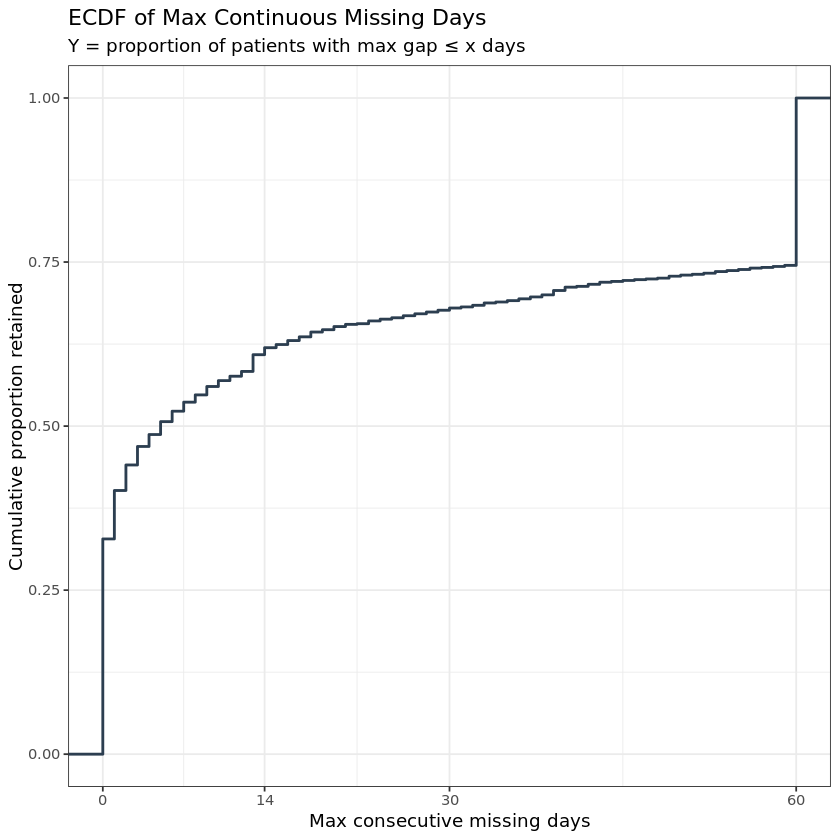

In [66]:
p_ecdf <- gap_summary |>
  mutate(max_gap = pmin(max_gap, 60)) |>
  ggplot(aes(x = max_gap)) +
  stat_ecdf(color = "#2C3E50", linewidth = 0.8) +
  scale_x_continuous(limits = c(0, 60),
                     breaks = c(0, 14, 30, 60)) +
  #scale_y_continuous(labels = scales::percent) +
  labs(title    = "ECDF of Max Continuous Missing Days",
       subtitle = "Y = proportion of patients with max gap ≤ x days",
       x = "Max consecutive missing days",
       y = "Cumulative proportion retained") +
  theme_bw(base_size = 11)
p_ecdf
#ggsave(p_ecdf, filename = paste0(path.out, 'activity_missing_gap.png'), width = 9, height = 5);


[1] "person_id"     "first_date"    "last_date"     "followup_days"
[5] "total_missing" "n_gaps"        "max_gap"       "mean_gap"     
[9] "gap_lengths"